# Taller Final – Minería de Datos
## Segmentación de clientes con K-Means (Mall Customers Dataset)

**Objetivo general:** desarrollar un modelo de segmentación de clientes con K-Means, evaluándolo con el método del codo y el coeficiente de silueta, para analizar patrones de comportamiento y apoyar decisiones de marketing.

**Dataset:** [Mall Customers – Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) (archivo `Mall_Customers.csv`, 200 clientes).

> Para ejecutar: deja `Mall_Customers.csv` en la misma carpeta de este cuaderno (en Colab, súbelo con el panel de archivos).

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Parte 1 – Exploración de datos
### 1.1 Cargar el dataset

In [2]:
df = pd.read_csv("Mall_Customers.csv")

# Algunas versiones del archivo traen la columna 'Genre' en lugar de 'Gender'
df = df.rename(columns={"Genre": "Gender"})

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [4]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0


### 1.2 Identificar variables relevantes

In [5]:
print("Columnas:", list(df.columns))
print("\nDistribución por género:")
print(df["Gender"].value_counts())

Columnas: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Distribución por género:
Gender
Female    112
Male       88
Name: count, dtype: int64


| Variable | Tipo | ¿Útil para segmentar? |
|---|---|---|
| `CustomerID` | Identificador | **No**: es solo un consecutivo, no describe al cliente. |
| `Gender` | Categórica | Poco: habría que codificarla y K-Means trabaja con distancias euclidianas, no es ideal para variables binarias. |
| `Age` | Numérica | Sí, como variable de apoyo para describir los grupos. |
| `Annual Income (k$)` | Numérica | **Sí**: capacidad económica del cliente. |
| `Spending Score (1-100)` | Numérica | **Sí**: comportamiento de compra en el centro comercial. |

### 1.3 Análisis descriptivo básico

In [6]:
df.describe().round(2)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


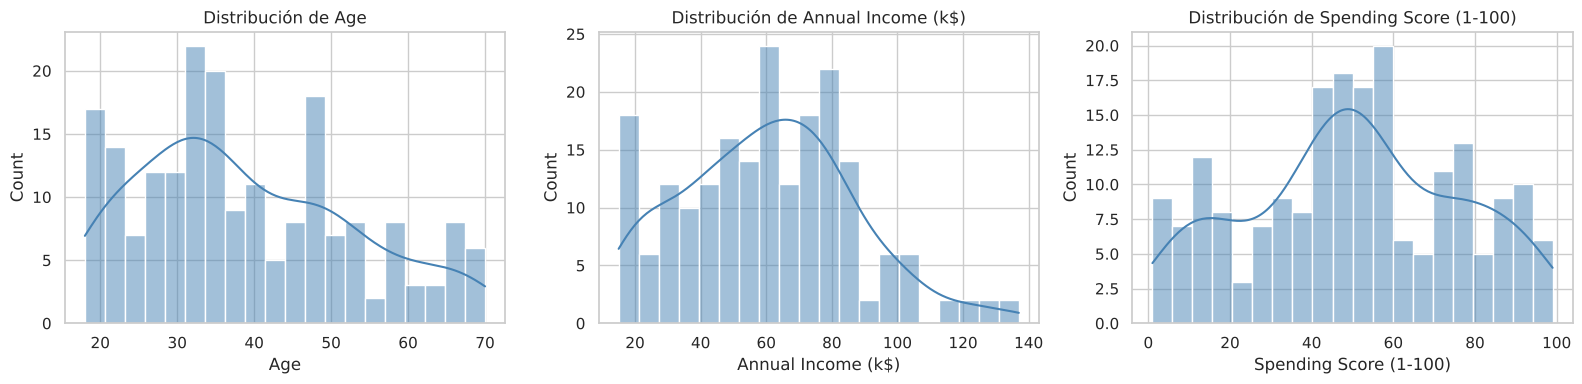

In [7]:
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, bins=20, ax=ax, color="steelblue")
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

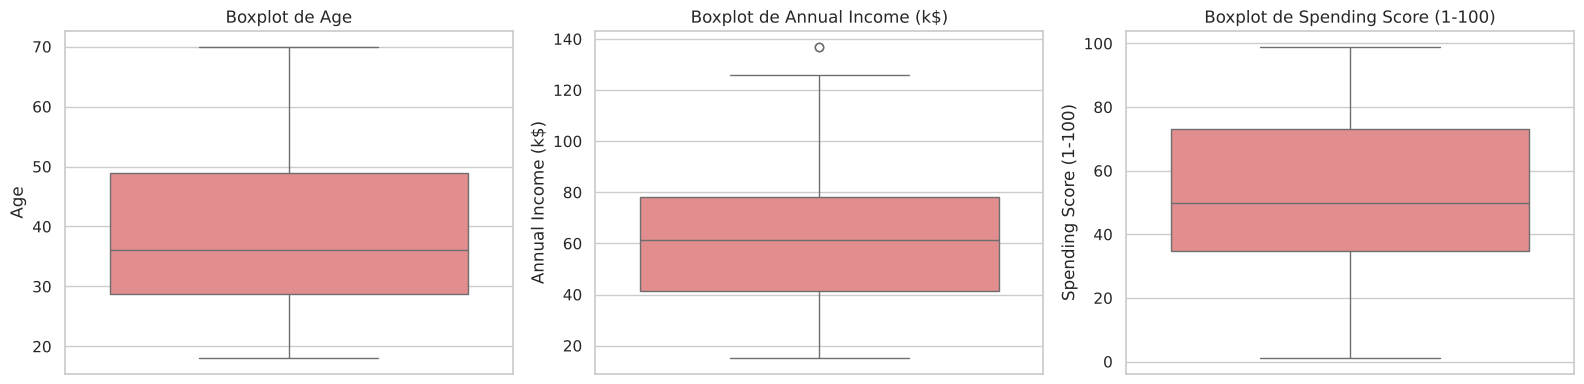

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

In [9]:
# Detección de atípicos con el criterio IQR (1.5 * rango intercuartílico)
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: límites [{lim_inf:.2f}, {lim_sup:.2f}] -> {len(atipicos)} atípicos {atipicos[col].tolist()}")

Age: límites [-1.62, 79.38] -> 0 atípicos []
Annual Income (k$): límites [-13.25, 132.75] -> 2 atípicos [137, 137]
Spending Score (1-100): límites [-22.62, 130.38] -> 0 atípicos []


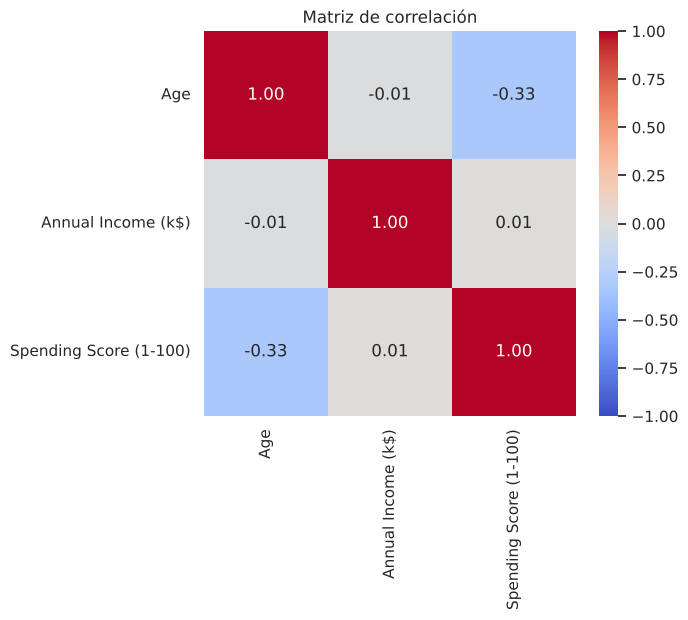

In [10]:
# Matriz de correlación
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

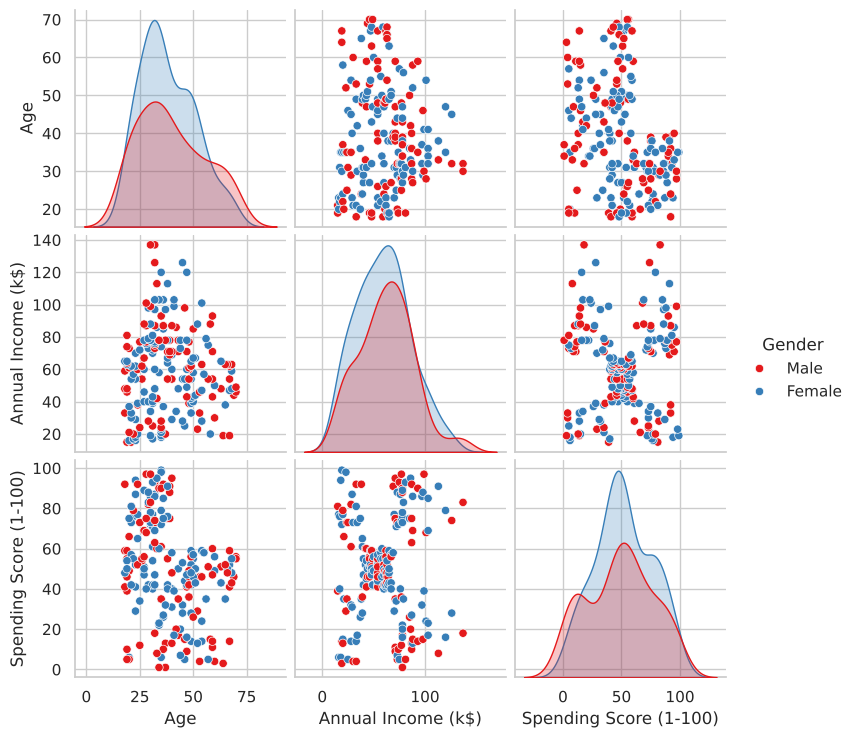

In [11]:
# Relaciones entre pares de variables
sns.pairplot(df, vars=num_cols, hue="Gender", diag_kind="kde", palette="Set1")
plt.show()

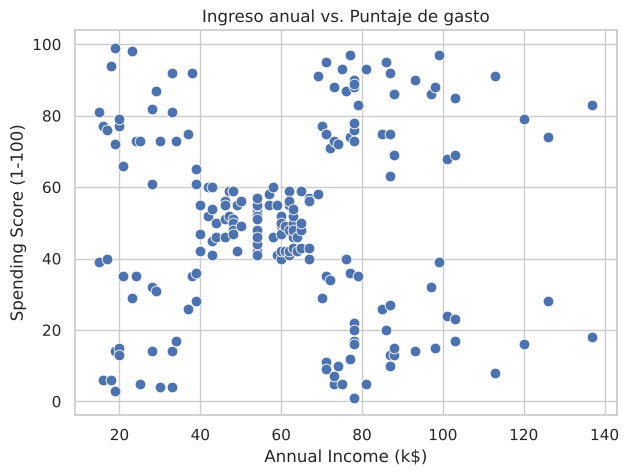

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", s=60)
plt.title("Ingreso anual vs. Puntaje de gasto")
plt.show()

### Pregunta 1: ¿Qué variables son más adecuadas para segmentar clientes?

Las más adecuadas son **`Annual Income (k$)`** y **`Spending Score (1-100)`**:

- Son numéricas y continuas, que es lo que necesita K-Means (trabaja con distancias euclidianas).
- Tienen interpretación directa de negocio: una mide **cuánto puede gastar** el cliente y la otra **cuánto gasta realmente**.
- En el gráfico de dispersión se ven a simple vista **cinco nubes de puntos** separadas, lo cual indica que contienen estructura de grupos.
- Su correlación es prácticamente cero (≈ 0.01), así que aportan información diferente y no redundante.

`Age` se usa como variable descriptiva para caracterizar los clusters. `CustomerID` se descarta (es un identificador) y `Gender` no se usa porque es categórica binaria y no mejora la separación de los grupos.

### Pregunta 2: ¿Se identifican valores atípicos?

Con el criterio IQR solo aparecen **2 valores atípicos**, ambos en `Annual Income (k$)` con un ingreso de **137 k$** (el límite superior es 132.75 k$). `Age` y `Spending Score` no presentan atípicos.

Se decide **conservarlos**: son ingresos posibles y reales (clientes de muy alto poder adquisitivo), no errores de digitación, y son solo 2 de 200 registros (1%). Además, el dataset no tiene valores nulos ni duplicados.

### Pregunta 3: ¿Qué tipo de relaciones se observan entre las variables?

- **Edad vs. Puntaje de gasto:** correlación **negativa moderada (≈ −0.33)**. Los clientes jóvenes tienden a tener un puntaje de gasto más alto; a partir de los ~40 años casi no hay puntajes altos.
- **Ingreso vs. Puntaje de gasto:** correlación lineal **casi nula (≈ 0.01)**, pero la relación **no es lineal**: el diagrama de dispersión muestra grupos bien definidos (forma de "X" o de cinco nubes). Esto demuestra que la correlación no captura todo y justifica usar clustering.
- **Edad vs. Ingreso:** correlación prácticamente nula; el ingreso no depende de la edad en este dataset.
- **Género:** hay más mujeres (112) que hombres (88), pero las distribuciones de ingreso y gasto son muy similares entre ambos.

# Parte 2 – Preprocesamiento
Se seleccionan las dos variables de segmentación y se normalizan con `StandardScaler` (media 0, desviación estándar 1).

In [13]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Antes del escalado  -> media:", X.mean(axis=0).round(2), " desv:", X.std(axis=0).round(2))
print("Después del escalado -> media:", X_scaled.mean(axis=0).round(2), " desv:", X_scaled.std(axis=0).round(2))
pd.DataFrame(X_scaled, columns=features).head()

Antes del escalado  -> media: [60.56 50.2 ]  desv: [26.2  25.76]
Después del escalado -> media: [-0. -0.]  desv: [1. 1.]


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


### Pregunta: ¿Por qué es necesario escalar las variables en el algoritmo K-Means?

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**. Si las variables están en escalas distintas, la que tenga números más grandes o mayor rango **domina el cálculo de la distancia** y el algoritmo prácticamente ignora las demás.

Por ejemplo, si se usara la edad (18–70) junto con un ingreso expresado en pesos (millones), la diferencia de ingresos aplastaría cualquier diferencia de edad. Con `StandardScaler` cada variable queda con **media 0 y desviación estándar 1**, de modo que todas **pesan lo mismo** y los clusters reflejan patrones reales y no las unidades de medida. En este dataset las dos variables tienen rangos parecidos (15–137 y 1–99), pero escalar sigue siendo la buena práctica y es indispensable si se agregan más variables.

# Parte 3 – Método del codo
Se entrena K-Means para K = 1 … 10 y se registra la **inercia** (WCSS: suma de distancias al cuadrado de cada punto a su centroide).

In [14]:
K_range = range(1, 11)
inercias = []
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

pd.DataFrame({"K": list(K_range), "Inercia (WCSS)": np.round(inercias, 2)})

,K,Inercia (WCSS)
0,1,400.00
1,2,269.69
2,3,157.70
3,4,108.92
4,5,65.57
5,6,55.06
6,7,44.86
7,8,37.23
8,9,32.39
9,10,29.98


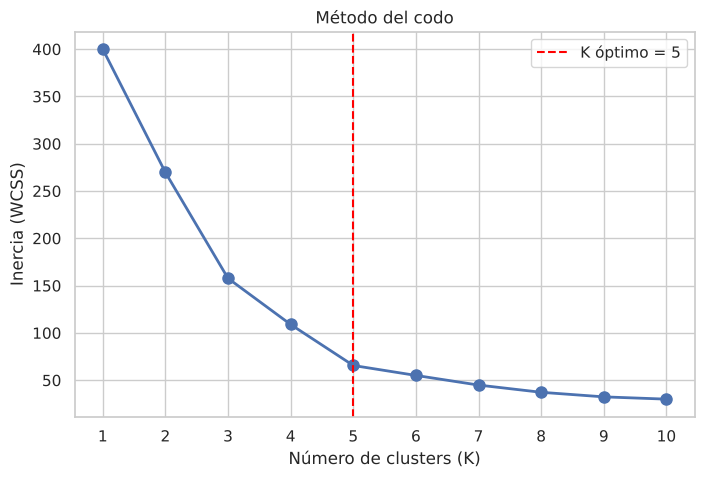

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(K_range, inercias, "o-", linewidth=2, markersize=8)
plt.axvline(5, color="red", linestyle="--", label="K óptimo = 5")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.title("Método del codo")
plt.xticks(list(K_range))
plt.legend()
plt.show()

In [16]:
# Reducción de la inercia al pasar de K-1 a K (ayuda a ver dónde se "dobla" el codo)
reduccion = [None] + [round((inercias[i-1] - inercias[i]) / inercias[i-1] * 100, 1) for i in range(1, len(inercias))]
pd.DataFrame({"K": list(K_range), "Inercia": np.round(inercias, 2), "% reducción vs K-1": reduccion})

,K,Inercia,% reducción vs K-1
0,1,400.00,NaN
1,2,269.69,32.6
2,3,157.70,41.5
3,4,108.92,30.9
4,5,65.57,39.8
5,6,55.06,16.0
6,7,44.86,18.5
7,8,37.23,17.0
8,9,32.39,13.0
9,10,29.98,7.4


### Pregunta: ¿Por qué valores cercanos a cero indican mejor ajuste?

La inercia (WCSS) es la suma de las distancias al cuadrado entre cada cliente y el centroide de su cluster:

$$WCSS = \sum_{j=1}^{K} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$$

Si es cercana a cero, significa que los puntos están **muy pegados a su centroide**, es decir, los clusters son **compactos y homogéneos** (los clientes de un mismo grupo se parecen mucho entre sí).

**Precaución:** la inercia siempre baja al aumentar K, y llega exactamente a 0 cuando K = número de datos (cada cliente es su propio cluster), lo cual no sirve para nada. Por eso no se busca el mínimo absoluto, sino el punto donde agregar más clusters deja de mejorar significativamente: el **codo**.

### Pregunta: ¿Cómo se identifica el punto óptimo de K?

Se busca el **"codo"** de la curva: el valor de K a partir del cual la inercia deja de caer bruscamente y empieza a bajar de forma lenta y casi lineal.

En este caso:
- De K=4 a K=5 la inercia cae de ≈ 108.9 a ≈ 65.6 (**≈ 40 % menos**).
- De K=5 a K=6 solo baja a ≈ 55.1 (**≈ 16 %**), y las caídas siguientes son cada vez menores.

Por lo tanto el codo está en **K = 5**: agregar un sexto cluster aporta poca mejora a cambio de más complejidad.

# Parte 4 – Coeficiente de silueta
(La silueta requiere al menos 2 clusters, por eso K empieza en 2.)

In [17]:
K_sil = range(2, 11)
siluetas = []
for k in K_sil:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, labels))

tabla_sil = pd.DataFrame({"K": list(K_sil), "Silueta": np.round(siluetas, 4)})
tabla_sil

,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


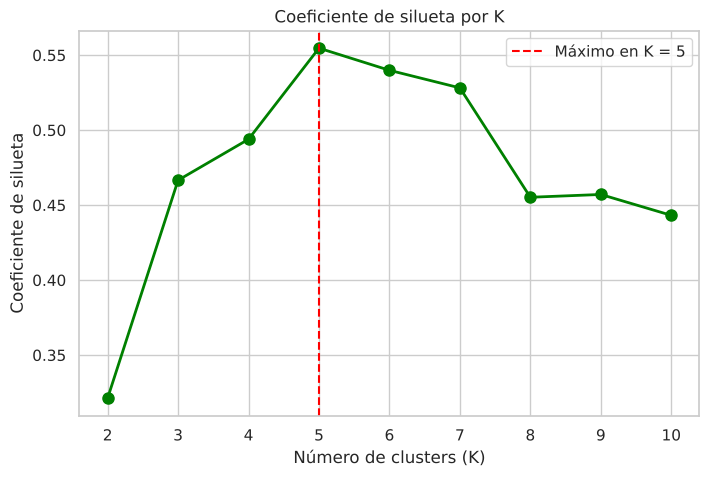

K con mayor silueta: 5  (silueta = 0.5547)


In [18]:
k_opt_sil = list(K_sil)[int(np.argmax(siluetas))]
plt.figure(figsize=(8, 5))
plt.plot(K_sil, siluetas, "o-", color="green", linewidth=2, markersize=8)
plt.axvline(k_opt_sil, color="red", linestyle="--", label=f"Máximo en K = {k_opt_sil}")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Coeficiente de silueta")
plt.title("Coeficiente de silueta por K")
plt.xticks(list(K_sil))
plt.legend()
plt.show()
print(f"K con mayor silueta: {k_opt_sil}  (silueta = {max(siluetas):.4f})")

### Pregunta: ¿Qué mide el coeficiente de silueta?

Mide **qué tan bien asignado está cada punto a su cluster**, combinando dos ideas:

- **Cohesión** $a(i)$: distancia promedio del punto a los demás puntos de **su propio** cluster.
- **Separación** $b(i)$: distancia promedio del punto a los puntos del **cluster vecino más cercano**.

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}, \qquad -1 \le s(i) \le 1$$

El coeficiente del modelo es el promedio de $s(i)$ sobre todos los puntos. A diferencia de la inercia, **no mejora automáticamente al aumentar K**, por eso sirve para comparar valores de K.

### Pregunta: ¿Qué significa un valor cercano a 1?

Que $a(i)$ es mucho menor que $b(i)$: el punto está **muy cerca de los miembros de su cluster y lejos del cluster vecino**. Si el promedio es cercano a 1, los clusters son **compactos y bien separados**; la segmentación es clara.

### Pregunta: ¿Qué implica un valor cercano a 0 o negativo?

- **Cercano a 0:** el punto está casi a la misma distancia de su cluster que del vecino, es decir, está **en la frontera** entre dos grupos. Un promedio cercano a 0 indica clusters **solapados** o una estructura de grupos débil.
- **Negativo:** el punto está **más cerca de otro cluster que del suyo**, por lo que probablemente está **mal asignado**. Un promedio negativo indica que el valor de K o el modelo no son adecuados.

### Pregunta: ¿Coincide el valor óptimo de K con el método del codo? Justifique.

**Sí, coinciden en K = 5.**

- El método del codo muestra el quiebre de la curva en K = 5 (después la inercia baja muy poco).
- El coeficiente de silueta alcanza su **máximo en K = 5 (≈ 0.555)**; para K = 4 es ≈ 0.494 y para K = 6 baja a ≈ 0.540.

Que dos métricas con criterios distintos (compacidad en el codo; compacidad + separación en la silueta) lleguen al mismo resultado da **confianza** en la elección. Además, una silueta de ≈ 0.55 se considera una estructura de clusters **razonablemente fuerte**, y es coherente con las cinco nubes que se veían en el diagrama de dispersión de la Parte 1.

# Parte 5 – Modelo K-Means con K = 5
### 5.1 Entrenar el modelo y asignar clusters

In [19]:
K_FINAL = 5
kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Silueta del modelo final:", round(silhouette_score(X_scaled, df["Cluster"]), 4))
print("\nClientes por cluster:")
print(df["Cluster"].value_counts().sort_index())
df.head(10)

Silueta del modelo final: 0.5547

Clientes por cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


### 5.2 Obtener los centroides
Los centroides se calculan en la escala normalizada; con `inverse_transform` se regresan a las unidades originales para poder interpretarlos.

In [20]:
centroides_esc = kmeans.cluster_centers_
centroides = pd.DataFrame(scaler.inverse_transform(centroides_esc), columns=features).round(2)
centroides.index.name = "Cluster"

print("Centroides (escala normalizada):")
print(pd.DataFrame(centroides_esc, columns=features).round(3))
print("\nCentroides (escala original):")
centroides

Centroides (escala normalizada):
   Annual Income (k$)  Spending Score (1-100)
0              -0.201                  -0.026
1               0.992                   1.240
2              -1.330                   1.132
3               1.055                  -1.284
4              -1.308                  -1.137

Centroides (escala original):


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


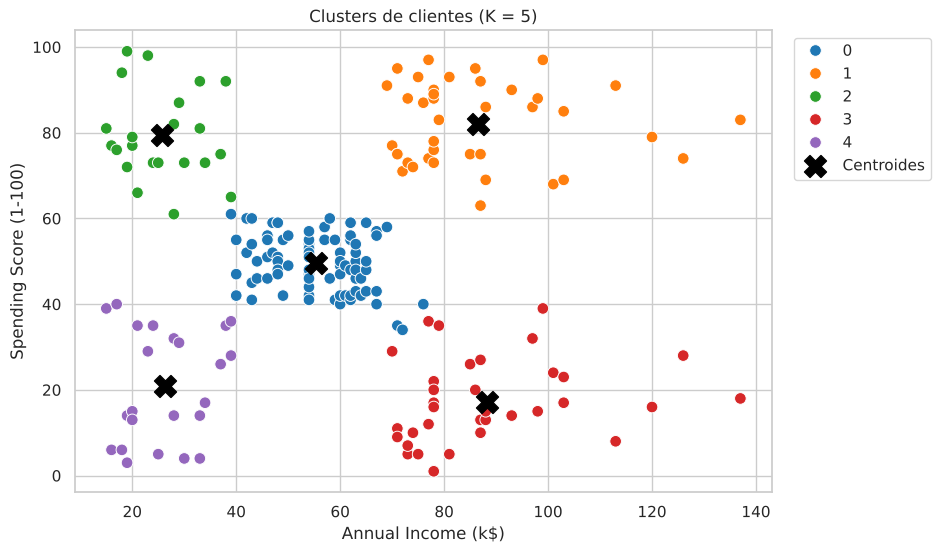

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", s=70)
plt.scatter(centroides.iloc[:, 0], centroides.iloc[:, 1], c="black", s=250, marker="X", label="Centroides")
plt.title("Clusters de clientes (K = 5)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [22]:
# Perfil promedio de cada cluster (incluye la edad y el género como variables descriptivas)
perfil = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_prom=("Age", "mean"),
    Ingreso_prom=("Annual Income (k$)", "mean"),
    Gasto_prom=("Spending Score (1-100)", "mean"),
    Pct_mujeres=("Gender", lambda g: (g == "Female").mean() * 100),
).round(1)
perfil

,Clientes,Edad_prom,Ingreso_prom,Gasto_prom,Pct_mujeres
Cluster,,,,,
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
2,22,25.3,25.7,79.4,59.1
3,35,41.1,88.2,17.1,45.7
4,23,45.2,26.3,20.9,60.9


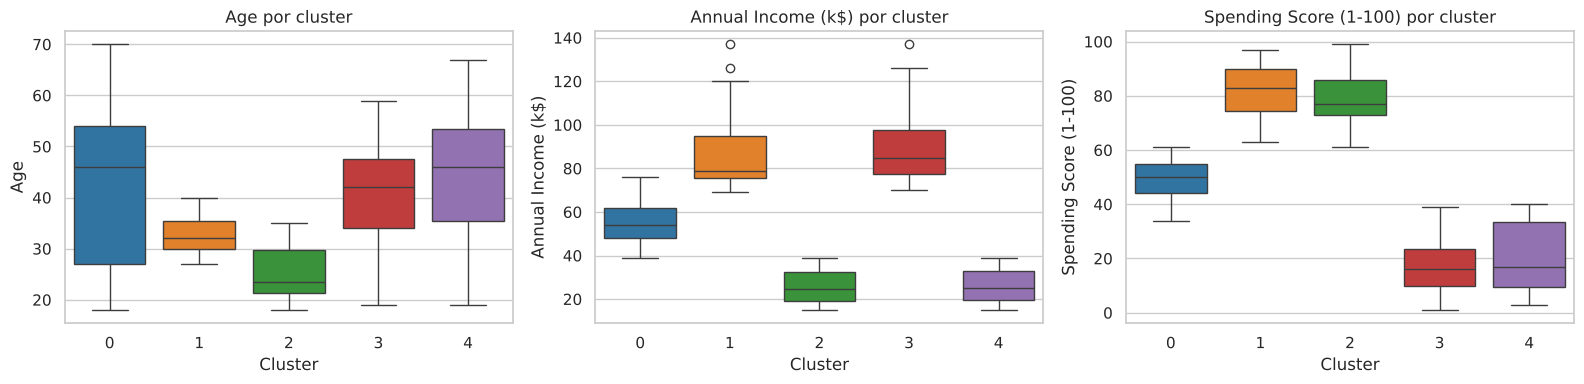

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Cluster", y=col, palette="tab10", ax=ax)
    ax.set_title(f"{col} por cluster")
plt.tight_layout()
plt.show()

### Pregunta: ¿Qué representa cada cluster?

Cada cluster es un **grupo de clientes con un comportamiento de ingreso y gasto similar**, y su centroide es el "cliente típico" del grupo. Según los centroides obtenidos (los números de cluster pueden cambiar de orden si cambia la versión de scikit-learn, pero los grupos son los mismos):

| Grupo | Ingreso | Gasto | Edad prom. | Clientes | Qué representa |
|---|---|---|---|---|---|
| A | Alto (≈ 86 k$) | Alto (≈ 82) | ≈ 33 | 39 | Clientes con dinero que gastan mucho. |
| B | Medio (≈ 55 k$) | Medio (≈ 50) | ≈ 43 | 81 | El cliente "típico" del centro comercial. |
| C | Bajo (≈ 26 k$) | Alto (≈ 79) | ≈ 25 | 22 | Jóvenes que gastan más de lo que su ingreso sugiere. |
| D | Alto (≈ 88 k$) | Bajo (≈ 17) | ≈ 41 | 35 | Tienen capacidad de compra pero casi no gastan aquí. |
| E | Bajo (≈ 26 k$) | Bajo (≈ 21) | ≈ 45 | 23 | Bajo ingreso y bajo gasto; compran solo lo necesario. |

### Pregunta: ¿Qué diferencias existen entre los grupos obtenidos?

- **Por ingreso:** hay tres niveles claros: bajo (≈ 26 k$), medio (≈ 55 k$) y alto (≈ 87 k$).
- **Por gasto:** dentro de los niveles de ingreso alto y bajo, los clientes se dividen en dos extremos (gasto alto vs. gasto bajo). Es decir, **tener más ingreso no implica gastar más**: el grupo de ingreso alto y gasto bajo lo demuestra.
- **Por edad:** los grupos de **gasto alto son los más jóvenes** (≈ 25 y ≈ 33 años), mientras que los de gasto bajo son mayores (≈ 41 y ≈ 45 años), lo que confirma la correlación negativa entre edad y gasto vista en la Parte 1.
- **Por tamaño:** el grupo promedio concentra ≈ 40 % de los clientes (81); los otros cuatro tienen entre 22 y 39 clientes.
- **Por género:** la proporción de mujeres es parecida en todos los grupos, así que el género no es lo que diferencia los segmentos.

# Parte 6 – Interpretación de negocio
Se asigna un perfil a cada cluster **automáticamente** comparando su centroide con la media general (así el código funciona aunque el número del cluster cambie).

In [24]:
ing_media = df["Annual Income (k$)"].mean()
gas_media = df["Spending Score (1-100)"].mean()
ing_std = df["Annual Income (k$)"].std()
gas_std = df["Spending Score (1-100)"].std()

def asignar_perfil(ingreso, gasto):
    # Se considera "medio" lo que está a menos de media desviación estándar de la media
    ing = "alto" if ingreso > ing_media + 0.5 * ing_std else "bajo" if ingreso < ing_media - 0.5 * ing_std else "medio"
    gas = "alto" if gasto > gas_media + 0.5 * gas_std else "bajo" if gasto < gas_media - 0.5 * gas_std else "medio"
    if ing == "alto" and gas == "alto":
        return "Clientes de alto valor"
    if ing == "alto" and gas == "bajo":
        return "Clientes con potencial"
    if ing == "bajo" and gas == "bajo":
        return "Clientes de bajo valor"
    if ing == "bajo" and gas == "alto":
        return "Clientes impulsivos (sensibles al precio)"
    return "Clientes promedio"

perfiles = {c: asignar_perfil(row.iloc[0], row.iloc[1]) for c, row in centroides.iterrows()}
df["Perfil"] = df["Cluster"].map(perfiles)

resumen = perfil.copy()
resumen.insert(0, "Perfil", resumen.index.map(perfiles))
resumen

,Perfil,Clientes,Edad_prom,Ingreso_prom,Gasto_prom,Pct_mujeres
Cluster,,,,,,
0,Clientes promedio,81,42.7,55.3,49.5,59.3
1,Clientes de alto valor,39,32.7,86.5,82.1,53.8
2,Clientes impulsivos (sensibles al precio),22,25.3,25.7,79.4,59.1
3,Clientes con potencial,35,41.1,88.2,17.1,45.7
4,Clientes de bajo valor,23,45.2,26.3,20.9,60.9


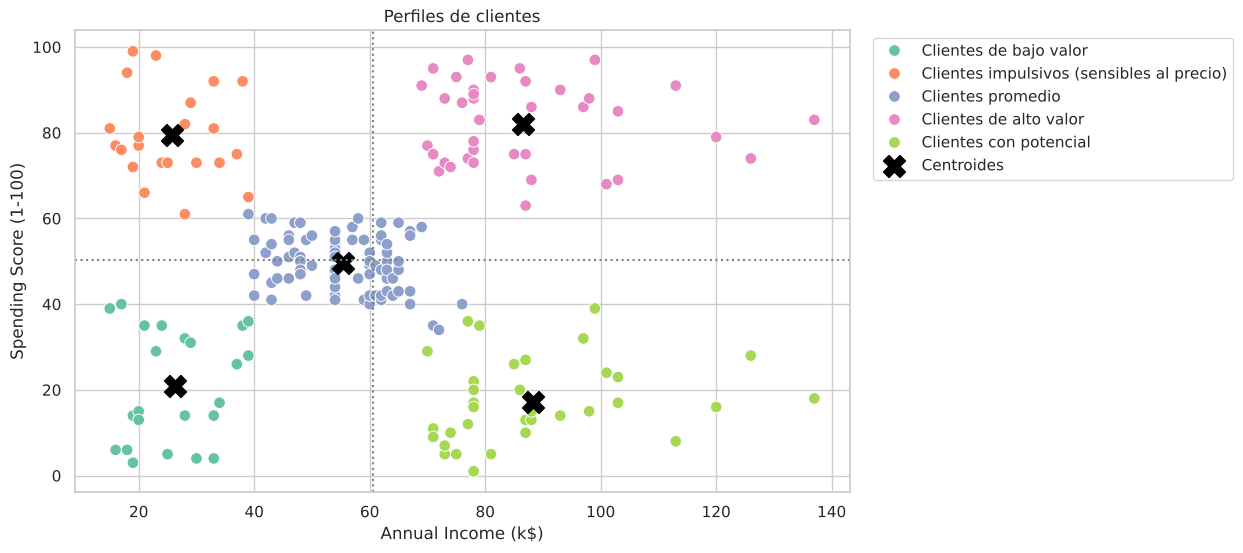

In [25]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Perfil", palette="Set2", s=70)
plt.scatter(centroides.iloc[:, 0], centroides.iloc[:, 1], c="black", s=250, marker="X", label="Centroides")
plt.axvline(ing_media, color="gray", linestyle=":")
plt.axhline(gas_media, color="gray", linestyle=":")
plt.title("Perfiles de clientes")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

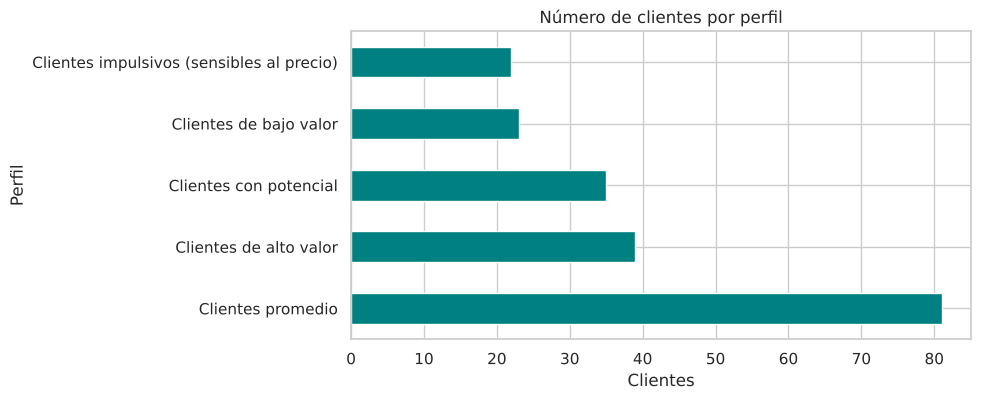

In [26]:
df["Perfil"].value_counts().plot(kind="barh", color="teal", figsize=(8, 4))
plt.title("Número de clientes por perfil")
plt.xlabel("Clientes")
plt.show()

### Clasificación de los clusters en perfiles

| Perfil | Ingreso / Gasto | Clientes |
|---|---|---|
| **Clientes de alto valor** | Alto / Alto | 39 |
| **Clientes promedio** | Medio / Medio | 81 |
| **Clientes de bajo valor** | Bajo / Bajo | 23 |
| **Clientes con potencial** | Alto / Bajo | 35 |
| **Clientes impulsivos (sensibles al precio)** | Bajo / Alto | 22 |

El taller sugiere cuatro perfiles, pero K-Means encontró **cinco** grupos; el quinto (ingreso bajo y gasto alto) no encaja en ninguno de los cuatro, por lo que se le da un nombre propio en lugar de forzarlo.

### Pregunta: ¿Qué estrategias de marketing se podrían aplicar a cada grupo?

**Clientes de alto valor (ingreso alto, gasto alto, ≈ 33 años)**
- Programa de fidelización VIP: puntos, acceso anticipado a lanzamientos, eventos exclusivos.
- Atención personalizada y productos premium; el objetivo es **retenerlos**, no necesariamente atraerlos.

**Clientes promedio (ingreso medio, gasto medio, ≈ 43 años)**
- Es el grupo más grande: campañas masivas, promociones de temporada y combos.
- Venta cruzada (cross-selling) y tarjetas de puntos para subir gradualmente su gasto.

**Clientes de bajo valor (ingreso bajo, gasto bajo, ≈ 45 años)**
- Ofertas de precio bajo, descuentos en productos básicos y marcas propias.
- Comunicación de bajo costo (correo, redes); no conviene invertir mucho presupuesto en ellos.

**Clientes con potencial (ingreso alto, gasto bajo, ≈ 41 años)**
- Investigar por qué no compran (encuestas): ¿no encuentran lo que buscan? ¿compran en la competencia?
- Ofrecer productos de calidad y conveniencia (servicios exclusivos, parqueadero, experiencias), campañas de calidad más que de descuento, e incentivos de primera compra.

**Clientes impulsivos / sensibles al precio (ingreso bajo, gasto alto, ≈ 25 años)**
- Promociones flash, cupones y opciones de pago a cuotas.
- Marketing en redes sociales y tendencias; cuidar no fomentar sobreendeudamiento.

### Pregunta: ¿Qué segmento representa mayor oportunidad de crecimiento?

El segmento de **Clientes con potencial (ingreso alto, gasto bajo)**.

- Son **35 clientes** (≈ 17,5 % del total) con un ingreso promedio de ≈ **88 k$**, similar al de los clientes de alto valor, pero con un puntaje de gasto de solo ≈ **17**.
- Es decir, **tienen el dinero pero no lo están gastando en el centro comercial**. La diferencia de gasto frente al grupo de alto valor (≈ 82 vs. ≈ 17) es el margen que se puede capturar.
- Los clientes de alto valor ya gastan casi al máximo y los de bajo ingreso tienen un límite económico, así que el **mayor crecimiento posible** está en convertir a los "clientes con potencial" en "clientes de alto valor".

# Parte 7 – Despliegue con Streamlit

La aplicación está en el archivo **`app.py`** (en la misma carpeta que este cuaderno y `Mall_Customers.csv`). Permite:

1. Visualizar el método del codo (y la silueta).
2. Mostrar los clusters generados.
3. Ingresar un nuevo cliente.
4. Clasificarlo automáticamente en un cluster y mostrar su perfil y estrategia.

**Ejecución:**
```bash
pip install -r requirements.txt
streamlit run app.py
```
La app se abre en `http://localhost:8501`.

A continuación se prueba en el cuaderno la misma lógica de clasificación que usa la app:

In [27]:
def clasificar_cliente(ingreso, gasto):
    nuevo = scaler.transform([[ingreso, gasto]])   # se escala con el MISMO scaler del entrenamiento
    cluster = int(kmeans.predict(nuevo)[0])
    return cluster, perfiles[cluster]

for ingreso, gasto in [(120, 90), (90, 10), (20, 85), (55, 50), (20, 10)]:
    c, p = clasificar_cliente(ingreso, gasto)
    print(f"Ingreso {ingreso:>3} k$, gasto {gasto:>2} -> Cluster {c}: {p}")

Ingreso 120 k$, gasto 90 -> Cluster 1: Clientes de alto valor
Ingreso  90 k$, gasto 10 -> Cluster 3: Clientes con potencial
Ingreso  20 k$, gasto 85 -> Cluster 2: Clientes impulsivos (sensibles al precio)
Ingreso  55 k$, gasto 50 -> Cluster 0: Clientes promedio
Ingreso  20 k$, gasto 10 -> Cluster 4: Clientes de bajo valor


# Conclusiones

1. Las variables que mejor segmentan a los clientes son el **ingreso anual** y el **puntaje de gasto**; la edad sirve para describir los grupos.
2. El escalado con `StandardScaler` garantiza que ambas variables pesen igual en la distancia euclidiana.
3. El **método del codo** y el **coeficiente de silueta** coinciden en **K = 5** (silueta ≈ 0.55), lo que da una segmentación sólida.
4. Se identificaron cinco perfiles: alto valor, promedio, bajo valor, con potencial e impulsivos.
5. La **mayor oportunidad de crecimiento** está en los clientes de ingreso alto y gasto bajo.
6. El modelo se desplegó en una aplicación **Streamlit** que clasifica nuevos clientes en tiempo real.